# Demo Notebook

This notebook demonstrates functions from `qml_lib.py`. Detailed experiments are in the experiments notebook, and interpretations are in the report.
That is why in this notebook there are just minimal explanations and selected functions from the library.

## Imports and RNG

In [1]:
import numpy as np
from functools import reduce
from itertools import combinations, product
from collections import defaultdict
import time

from scipy.sparse import csr_matrix, kron as sparse_kron, eye as sparse_eye

import pennylane as qml

rng = np.random.default_rng(23)


## Single-qubit Pauli building blocks

Matrices used throughout. Defined as sparse matrices for memory efficiency.

In [2]:
I_SP = sparse_eye(2, format='csr')
X_SP = csr_matrix([[0, 1], [1, 0]])
Y_SP = csr_matrix([[0, -1j], [1j, 0]])
Z_SP = csr_matrix([[1, 0], [0, -1]])

SPARSE_MAP = {'I': I_SP, 'X': X_SP, 'Y': Y_SP, 'Z': Z_SP}
STATE_MAP  = {0: np.array([1, 0], dtype=complex),
              1: np.array([0, 1], dtype=complex)}


def pauli_string_to_matrix(s: str):
    """Sparse 2^n x 2^n matrix for a Pauli string like 'XYZI'."""
    return reduce(sparse_kron, (SPARSE_MAP[c] for c in s)).tocsr()


## Hamiltonian: 2D random Heisenberg on a 5×2 grid

Couplings $J_{\langle ij\rangle}$  are drawn uniformly from [0, 1] for each nearest neighbour edge. The term list `[(coeff, pauli_string), ...]` is the format I will reuse throughout: every other piece of the pipeline (Trotter, exact diagonalisation) uses it.


In [3]:
def heisenberg_2d_terms(n_rows, n_cols, rng):
    """2D random anti-ferromagnetic Heisenberg on an n_rows x n_cols grid."""
    n = n_rows * n_cols
    terms = []

    def idx(r, c):
        return r * n_cols + c

    for r in range(n_rows):
        for c in range(n_cols):
            # horizontal bond
            if c + 1 < n_cols:
                J = rng.uniform(0, 1)
                for P in 'XYZ':
                    s = ['I'] * n
                    s[idx(r, c)]     = P
                    s[idx(r, c + 1)] = P
                    terms.append((J, ''.join(s)))
            # vertical bond
            if r + 1 < n_rows:
                J = rng.uniform(0, 1)
                for P in 'XYZ':
                    s = ['I'] * n
                    s[idx(r, c)]     = P
                    s[idx(r + 1, c)] = P
                    terms.append((J, ''.join(s)))
    return terms


def build_hamiltonian(terms, n_qubits):
    """Compile a term list into (sparse H, pauli_strings, coeffs)."""
    pauli_strings, coeffs = [], []
    for c, s in terms:
        assert len(s) == n_qubits, (
            f"term '{s}' has length {len(s)} != n_qubits={n_qubits}")
        pauli_strings.append(s)
        coeffs.append(c)

    H_sparse = sum(c * pauli_string_to_matrix(s)
                   for c, s in zip(coeffs, pauli_strings)).tocsr()
    return H_sparse, pauli_strings, np.array(coeffs)


## Trotterised time evolution

We approximate `U = exp(-iHt)` with first-order Trotter: each term exp(-i $c_k \tau P_k$) is implemented by basis-rotating its into Z, accumulating parity with a CNOT ladder, applying $R_z$($2\theta$), then uncomputing.


In [ ]:
def apply_pauli_rotation(pauli_string, theta):
    """Apply e^{-i theta P}: basis-change -> CNOT ladder -> Rz(2theta) -> uncompute."""
    support = [(q, p) for q, p in enumerate(pauli_string) if p != 'I']
    if not support:
        return  # identity term: only contributes a global phase

    # Rotate each support qubit into the Z eigenbasis
    for q, p in support:
        if p == 'X':
            qml.Hadamard(wires=q)
        elif p == 'Y':
            qml.RX(np.pi / 2, wires=q)

    # CNOT ladder
    support_qubits = [q for q, _ in support]
    for i in range(len(support_qubits) - 1):
        qml.CNOT(wires=[support_qubits[i], support_qubits[i + 1]])

    # Rz on the last qubit in the support
    qml.RZ(2 * theta, wires=support_qubits[-1])

    # Uncompute CNOT ladder
    for i in reversed(range(len(support_qubits) - 1)):
        qml.CNOT(wires=[support_qubits[i], support_qubits[i + 1]])

    # Undo basis change
    for q, p in support:
        if p == 'X':
            qml.Hadamard(wires=q)
        elif p == 'Y':
            qml.RX(-np.pi / 2, wires=q)


def trotter_circuit(pauli_strings, coeffs, t, n_steps):
    """First-order Trotterised e^{-iHt} for H = Σ c_k P_k."""
    tau = t / n_steps
    for _ in range(n_steps):
        for s, c in zip(pauli_strings, coeffs):
            apply_pauli_rotation(s, c * tau)


def evolve_bitstring(x, pauli_strings, coeffs, t, n_steps):
    """Prepare |x> and apply Trotterised time evolution."""
    for q, bit in enumerate(x):
        if bit == 1:
            qml.PauliX(wires=q)
    trotter_circuit(pauli_strings, coeffs, t, n_steps)


## Hyperparameters and Hamiltonian instance

In [ ]:
# Hyperparameters 
n_qubits      = 10
t             = 2.0
n_trotter     = 30   # first-order Trotter steps
n_samples     = 500  
n_shots       = 1000
k_obs         = 3    # locality of feature basis and observable
n_obs_terms   = 10   # sparsity of alpha*

# Hamiltonian: 2D Heisenberg on a 5x2 grid 
H_terms = heisenberg_2d_terms(5, 2, rng)
H_sparse, H_pauli_strings, H_coeffs = build_hamiltonian(H_terms, n_qubits)
print(f"Hamiltonian: {len(H_pauli_strings)} Pauli terms on {n_qubits} qubits")

# Exact diagonalisation used  for computing y labels
eigvals, V = np.linalg.eigh(H_sparse.toarray())
Vdag   = V.conj().T
phases = np.exp(-1j * t * eigvals)


Hamiltonian: 39 Pauli terms on 10 qubits


## Feature basis and sparse observable

The feature basis is every weight $k_{obs}$ Pauli string on $n_{qubits}$
qubits. Its size is $\binom{n}{k} \cdot 3^k$. The unknown observable is a
random sparse vector $\alpha^*$ with `n_obs_terms` non-zero entries drawn from
that basis.


In [ ]:
def enumerate_k_local_paulis(k, n):
    """All weight-k Pauli strings on n qubits."""
    strings = []
    for positions in combinations(range(n), k):
        for paulis in product('XYZ', repeat=k):
            s = ['I'] * n
            for pos, p in zip(positions, paulis):
                s[pos] = p
            strings.append(''.join(s))
    return strings


feature_strings = enumerate_k_local_paulis(k_obs, n_qubits)
m = len(feature_strings)
print(f"Feature dimension m = C({n_qubits},{k_obs}) * 3^{k_obs} = {m}")

# Sparse unknown observable 
obs_idx    = rng.choice(m, n_obs_terms, replace=False)
obs_alphas = rng.uniform(-1, 1, n_obs_terms)
obs_strs   = [feature_strings[i] for i in obs_idx]

O_matrix = sum(a * pauli_string_to_matrix(s)
               for a, s in zip(obs_alphas, obs_strs)).tocsr()

alpha_true          = np.zeros(m)
alpha_true[obs_idx] = obs_alphas
B_true              = float(np.sum(np.abs(obs_alphas)))   # ||α*||_1

print(f"Observable: {n_obs_terms} non-zero terms, ||α*||_1 = {B_true:.4f}")


Feature dimension m = C(10,3) * 3^3 = 3240
Observable: 10 non-zero terms, ||α*||_1 = 4.7025


## Grouping Paulis by measurement basis

Many Pauli strings share the same per-qubit measurement basis (for
example, `XIZIZ...` and `XIZII...` both need X on qubit 0 and Z on
qubits 2, 4). One circuit run in that basis estimates all of them
simultaneously, which is what cuts down the shot cost.


In [22]:
def _basis_key(pauli_str):
    """Per-qubit measurement basis: X/Y/Z (treat I as Z)."""
    return tuple('Z' if p == 'I' else p for p in pauli_str)


# basis_key -> list of (pauli_index, support_qubits_tuple)
basis_groups = defaultdict(list)
for j, s in enumerate(feature_strings):
    support_qubits = tuple(q for q, p in enumerate(s) if p != 'I')
    basis_groups[_basis_key(s)].append((j, support_qubits))

print(f"Grouped {m} Pauli strings into {len(basis_groups)} measurement bases")
print(f"  -> ~{m / len(basis_groups):.1f} Paulis per circuit run on average")


Grouped 3240 Pauli strings into 1161 measurement bases
  -> ~2.8 Paulis per circuit run on average


## Quantum pipeline: state prep and basis sampling

Two QNodes:

* `evolved_state(x)` runs the Trotter circuit once and returns the
  full statevector.
* `sample_from_state(ψ, basis)` loads a pre-computed state, rotates
  into the requested measurement basis, and returns `n_shots` bitstring
  samples.

Splitting it this way means we Trotterise once per sample instead of
once per measurement basis.


In [23]:
dev_evolve  = qml.device('lightning.qubit', wires=n_qubits)
dev_measure = qml.device('lightning.qubit', wires=n_qubits, shots=n_shots)


@qml.qnode(dev_evolve)
def evolved_state(x_bits):
    """Run Trotter once, return the full state vector."""
    evolve_bitstring(x_bits, H_pauli_strings, H_coeffs, t, n_trotter)
    return qml.state()


@qml.qnode(dev_measure)
def sample_from_state(state_vec, basis_key):
    """Load a state, rotate into `basis_key`, sample all qubits."""
    qml.StatePrep(state_vec, wires=range(n_qubits))
    for q, b in enumerate(basis_key):
        if b == 'X':
            qml.Hadamard(wires=q)
        elif b == 'Y':
            qml.adjoint(qml.S)(wires=q)
            qml.Hadamard(wires=q)
        # 'Z' / 'I': no rotation
    return qml.sample(wires=range(n_qubits))


def compute_phi_shots(x_bits):
    """Trotter once, then sample in every measurement basis."""
    psi = np.asarray(evolved_state(x_bits))  # one Trotter run

    phi = np.zeros(m)
    for basis_key, members in basis_groups.items():
        samples = np.atleast_2d(sample_from_state(psi, basis_key))
        for j, support in members:
            if not support:
                phi[j] = 1.0
                continue
            bits = samples[:, list(support)].sum(axis=1) & 1
            phi[j] = float((1 - 2 * bits).mean())
    return phi


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


## Generate the dataset

For each random bitstring x:

* `φ(x)` is estimated from `n_shots` measurements per basis
  (shot-noisy, what a real device would give).
* `y = ⟨ψ_t|O|ψ_t⟩` is computed by exact diagonalisation.


In [ ]:
Phi = np.zeros((n_samples, m), dtype=float)
y   = np.zeros(n_samples, dtype=float)
X   = np.zeros((n_samples, n_qubits), dtype=int)

print(f"Generating {n_samples} shot-noisy samples "
      f"(n_shots={n_shots}, {len(basis_groups)} bases per sample) ...")
t0 = time.time()

for i in range(n_samples):
    if i % 25 == 0 and i > 0:
        elapsed = time.time() - t0
        rate = i / elapsed
        eta  = (n_samples - i) / rate
        print(f"  {i}/{n_samples}   ({rate:.2f} samples/s, ETA {eta:.0f}s)")

    x = rng.integers(0, 2, size=n_qubits)
    X[i]   = x
    Phi[i] = compute_phi_shots(x)

    # Label via exact diagonalisation
    psi0  = reduce(np.kron, (STATE_MAP[int(b)] for b in x))
    psi_t = V @ (phases * (Vdag @ psi0))
    y[i]  = np.vdot(psi_t, O_matrix @ psi_t).real

print(f"Done in {time.time() - t0:.1f}s.")


Generating 500 shot-noisy samples (n_shots=1000, 1161 bases per sample) ...
  25/500   (0.24 samples/s, ETA 2021s)
  50/500   (0.24 samples/s, ETA 1897s)
  75/500   (0.24 samples/s, ETA 1790s)
  100/500   (0.24 samples/s, ETA 1688s)
  125/500   (0.24 samples/s, ETA 1583s)
  150/500   (0.24 samples/s, ETA 1471s)
  175/500   (0.24 samples/s, ETA 1365s)
  200/500   (0.24 samples/s, ETA 1259s)
  225/500   (0.24 samples/s, ETA 1154s)
  250/500   (0.24 samples/s, ETA 1047s)
  275/500   (0.24 samples/s, ETA 942s)
  300/500   (0.24 samples/s, ETA 837s)
  325/500   (0.24 samples/s, ETA 730s)
  350/500   (0.24 samples/s, ETA 627s)
  375/500   (0.24 samples/s, ETA 524s)
  400/500   (0.24 samples/s, ETA 421s)
  425/500   (0.24 samples/s, ETA 315s)
  450/500   (0.24 samples/s, ETA 210s)
  475/500   (0.24 samples/s, ETA 104s)
Done in 2073.7s.


## Train/test split and model setup

In [36]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.linear_model import LassoCV, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch device: {device}")

torch.manual_seed(0)

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42)
Phi_tr, Phi_te, _, _ = train_test_split(
    Phi, y, test_size=0.2, random_state=42)

print(f"Train: {len(X_tr)}  Test: {len(X_te)}")
print(f"y train range: [{y_tr.min():.3f}, {y_tr.max():.3f}]   std = {y_tr.std():.3f}")


PyTorch device: cpu
Train: 400  Test: 100
y train range: [-0.223, 0.139]   std = 0.051


## MLP and training loop

A plain feed-forward network with ReLU activations and optional dropout, with a usual Adam training loop with per-epoch eval.

In [37]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden=(128, 128, 64), out_dim=1, dropout=0.0):
        super().__init__()
        layers = []
        prev = in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, out_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def train_mlp(model, X_tr_t, y_tr_t, X_te_t, y_te_t,
              epochs=400, lr=1e-3, batch_size=64, weight_decay=1e-5,
              verbose_every=50):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.MSELoss()
    loader = DataLoader(TensorDataset(X_tr_t, y_tr_t),
                        batch_size=batch_size, shuffle=True)

    history = {'train_mse': [], 'test_mse': []}
    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()

        model.eval()
        with torch.no_grad():
            tr_mse = loss_fn(model(X_tr_t), y_tr_t).item()
            te_mse = loss_fn(model(X_te_t), y_te_t).item()
        history['train_mse'].append(tr_mse)
        history['test_mse'].append(te_mse)

        if verbose_every and (ep + 1) % verbose_every == 0:
            print(f"  ep {ep+1:4d}   train MSE = {tr_mse:.5f}   test MSE = {te_mse:.5f}")
    return history


## Model 1: LASSO on φ(x)

This is the model the theory targets: `h(x) = w · φ(x)` with `‖w‖₁` controlled. Because α* is sparse and the features are an overcomplete Pauli basis, LASSO should recover the support.


In [38]:
lasso = LassoCV(cv=5, max_iter=10_000,
                alphas=np.logspace(-4, 0, 60), n_jobs=-1)
lasso.fit(Phi_tr, y_tr)

w_star          = lasso.coef_
y_pred_tr_lasso = lasso.predict(Phi_tr)
y_pred_te_lasso = lasso.predict(Phi_te)

mse_tr_lasso = mean_squared_error(y_tr, y_pred_tr_lasso)
mse_te_lasso = mean_squared_error(y_te, y_pred_te_lasso)
r2_tr_lasso  = r2_score(y_tr, y_pred_tr_lasso)
r2_te_lasso  = r2_score(y_te, y_pred_te_lasso)

print(f"LASSO on φ(x)  (n_shots = {n_shots}, ε ~ {1/np.sqrt(n_shots):.3f})")
print(f"  Best CV α   = {lasso.alpha_:.2e}   (||α*||_1 = {B_true:.3f})")
print(f"  Train MSE   = {mse_tr_lasso:.6f}   R² = {r2_tr_lasso:.4f}")
print(f"  Test  MSE   = {mse_te_lasso:.6f}   R² = {r2_te_lasso:.4f}")

recovered = np.where(w_star != 0)[0]
tp = len(set(recovered) & set(obs_idx))
print(f"  Support: {tp}/{n_obs_terms} true terms found "
      f"({len(recovered)} total non-zero)")
print(f"  ||w* - α*||_2 = {np.linalg.norm(w_star - alpha_true):.4f}")


LASSO on φ(x)  (n_shots = 1000, ε ~ 0.032)
  Best CV α   = 1.37e-04   (||α*||_1 = 4.703)
  Train MSE   = 0.000254   R² = 0.9030
  Test  MSE   = 0.000449   R² = 0.7820
  Support: 2/10 true terms found (71 total non-zero)
  ||w* - α*||_2 = 1.7782


## Model 2: NN on raw x

A small MLP given only the input bitstring. With 10 input bits and
no quantum side-information, it has to learn the entire `x ↦ y`
mapping from data.

We map `{0, 1} → {-1, +1}` before feeding x in; this is purely an
optimisation nicety (zero-centred inputs train better).


In [39]:
X_tr_signed = 2.0 * X_tr.astype(np.float32) - 1.0
X_te_signed = 2.0 * X_te.astype(np.float32) - 1.0

X_tr_t = torch.tensor(X_tr_signed,             dtype=torch.float32, device=device)
X_te_t = torch.tensor(X_te_signed,             dtype=torch.float32, device=device)
y_tr_t = torch.tensor(y_tr.astype(np.float32), dtype=torch.float32, device=device)
y_te_t = torch.tensor(y_te.astype(np.float32), dtype=torch.float32, device=device)

print(f"Training NN on raw x  ({n_qubits} -> 128 -> 128 -> 64 -> 1)")
nn_x   = MLP(in_dim=n_qubits, hidden=(128, 128, 64))
hist_x = train_mlp(nn_x, X_tr_t, y_tr_t, X_te_t, y_te_t,
                   epochs=400, lr=1e-3, weight_decay=1e-5)

nn_x.eval()
with torch.no_grad():
    y_pred_tr_nnx = nn_x(X_tr_t).cpu().numpy()
    y_pred_te_nnx = nn_x(X_te_t).cpu().numpy()

mse_tr_nnx = mean_squared_error(y_tr, y_pred_tr_nnx)
mse_te_nnx = mean_squared_error(y_te, y_pred_te_nnx)
r2_tr_nnx  = r2_score(y_tr, y_pred_tr_nnx)
r2_te_nnx  = r2_score(y_te, y_pred_te_nnx)

print(f"\nNN on raw x")
print(f"  Train MSE = {mse_tr_nnx:.6f}   R² = {r2_tr_nnx:.4f}")
print(f"  Test  MSE = {mse_te_nnx:.6f}   R² = {r2_te_nnx:.4f}")


Training NN on raw x  (10 -> 128 -> 128 -> 64 -> 1)
  ep   50   train MSE = 0.00001   test MSE = 0.00110
  ep  100   train MSE = 0.00004   test MSE = 0.00117
  ep  150   train MSE = 0.00001   test MSE = 0.00108
  ep  200   train MSE = 0.00003   test MSE = 0.00113
  ep  250   train MSE = 0.00002   test MSE = 0.00110
  ep  300   train MSE = 0.00001   test MSE = 0.00109
  ep  350   train MSE = 0.00003   test MSE = 0.00114
  ep  400   train MSE = 0.00004   test MSE = 0.00116

NN on raw x
  Train MSE = 0.000038   R² = 0.9853
  Test  MSE = 0.001164   R² = 0.4354


## Summary table

In [41]:
results = {
    'NN on x':       (mse_tr_nnx,   mse_te_nnx,   r2_tr_nnx,   r2_te_nnx),
    'LASSO on φ(x)': (mse_tr_lasso, mse_te_lasso, r2_tr_lasso, r2_te_lasso),
}

print(f"{'Model':<18s} {'Train MSE':>12s} {'Test MSE':>12s} {'Train R²':>10s} {'Test R²':>10s}")
print('─' * 66)
for name, (mtr, mte, rtr, rte) in results.items():
    print(f"{name:<18s} {mtr:>12.6f} {mte:>12.6f} {rtr:>10.4f} {rte:>10.4f}")

Model                 Train MSE     Test MSE   Train R²    Test R²
──────────────────────────────────────────────────────────────────
NN on x                0.000038     0.001164     0.9853     0.4354
LASSO on φ(x)          0.000254     0.000449     0.9030     0.7820


## Plots: model comparison, parity, learning curves

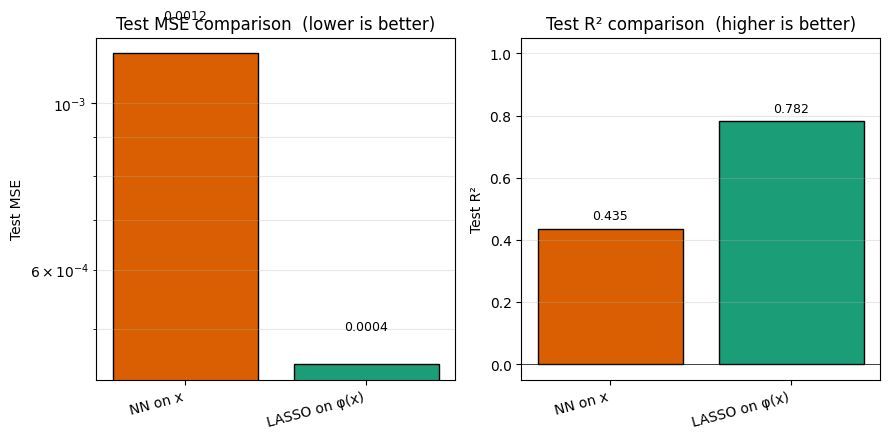

In [42]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))

names  = list(results.keys())
colors = ['#d95f02', '#1b9e77']

# Test MSE
ax = axes[0]
test_mses = [results[n][1] for n in names]
bars = ax.bar(names, test_mses, color=colors, edgecolor='black')
ax.set_ylabel('Test MSE')
ax.set_title('Test MSE comparison  (lower is better)')
ax.set_yscale('log')
for b, v in zip(bars, test_mses):
    ax.text(b.get_x() + b.get_width()/2, v * 1.1, f'{v:.4f}',
            ha='center', va='bottom', fontsize=9)
plt.setp(ax.get_xticklabels(), rotation=15, ha='right')
ax.grid(True, axis='y', alpha=0.3, which='both')

# Test R²
ax = axes[1]
test_r2 = [results[n][3] for n in names]
bars = ax.bar(names, test_r2, color=colors, edgecolor='black')
ax.set_ylabel('Test R²')
ax.set_title('Test R² comparison  (higher is better)')
ax.axhline(0, color='k', lw=0.5)
ax.set_ylim(min(min(test_r2) - 0.05, -0.05), 1.05)
for b, v in zip(bars, test_r2):
    y_off = 0.02 if v >= 0 else -0.05
    ax.text(b.get_x() + b.get_width()/2, v + y_off, f'{v:.3f}',
            ha='center', va='bottom' if v >= 0 else 'top', fontsize=9)
plt.setp(ax.get_xticklabels(), rotation=15, ha='right')
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


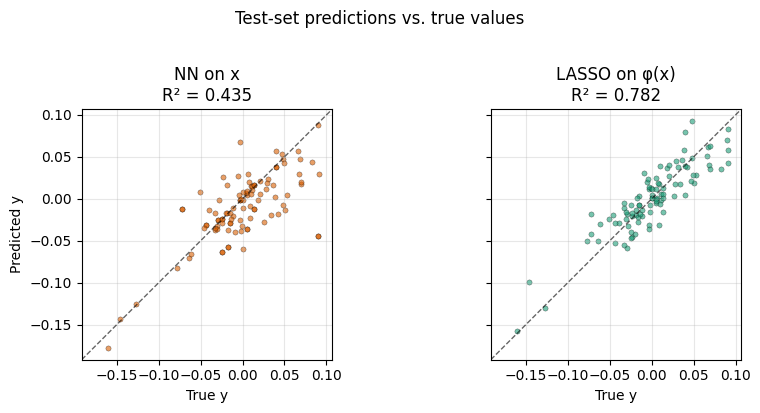

In [43]:
# Predictions-vs-true scatter (test set)
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)

preds = {
    'NN on x':       y_pred_te_nnx,
    'LASSO on φ(x)': y_pred_te_lasso,
}
colors = ['#d95f02', '#1b9e77']

lo = min(y_te.min(), *(p.min() for p in preds.values()))
hi = max(y_te.max(), *(p.max() for p in preds.values()))
pad = 0.05 * (hi - lo)

for ax, color, (key, y_pred) in zip(axes, colors, preds.items()):
    ax.scatter(y_te, y_pred, s=14, alpha=0.6, color=color,
               edgecolor='black', linewidth=0.3)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], 'k--', lw=1, alpha=0.6)
    ax.set_title(f"{key}\nR² = {results[key][3]:.3f}")
    ax.set_xlabel('True y')
    ax.grid(True, alpha=0.3)
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_aspect('equal')

axes[0].set_ylabel('Predicted y')
plt.suptitle('Test-set predictions vs. true values', y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

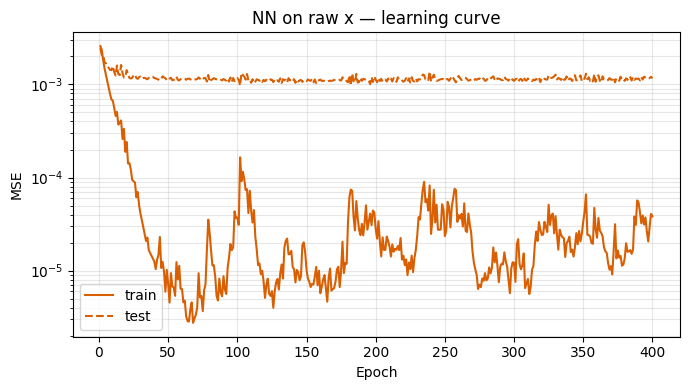

In [45]:
# NN learning curve (train + test MSE vs epoch)
fig, ax = plt.subplots(figsize=(7, 4))

epochs = np.arange(1, len(hist_x['train_mse']) + 1)
ax.plot(epochs, hist_x['train_mse'], color='#d95f02', lw=1.5, label='train')
ax.plot(epochs, hist_x['test_mse'],  color='#d95f02', lw=1.5, ls='--', label='test')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE')
ax.set_yscale('log')
ax.set_title('NN on raw x — learning curve')
ax.legend()
ax.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.show()